In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats


pd.options.display.max_columns = 999
pd.options.display.float_format = "{:.2f}".format

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

dataset1  = "/content/drive/MyDrive/BOOTACAMP'S FILE/FINAL PROJECT'S FILE/E-Commerce Revenue and Delivery Performance Analysis/E-commerce_Delivery_Shipping_Data_2026.csv"

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


# Business Understanding

# Problem Statement
Perusahaan memiliki keterlambatan pengiriman dari estimasi yang sudah ditentukan sebelumnya. Keterlambatan ini berpengaruh pada rating pelanggan yang jadi turun dan otomatis berpengaruh pada tingkat retur menjadi meningkat. Perusahaan perlu mengetahui carrier, gudang, dan kondisi apa yang paling banyak menyumbang keterlambatan, agar bisa memprioritaskan perbaikan operasional dan menekan kebocoran pendapatan dari return.

# Data Understanding

In [ ]:
df= pd.read_csv(dataset1)
df.head()

,order_id,order_date,customer_id,customer_segment,customer_city,customer_country,warehouse_id,warehouse_city,product_category,product_weight_kg,order_value_usd,shipping_method,carrier,distance_km,promised_delivery_days,actual_delivery_days,delivery_status,late_delivery,delivery_delay_days,shipping_cost_usd,package_size,payment_method,order_priority,weather_condition,customer_rating,return_requested,return_reason,delivery_attempts,warehouse_processing_hours,tracking_status
0,ORD-000001,2026-11-15,CUS-002353,Small Business,Tokyo,Japan,WH-004,Toronto,Home & Kitchen,8.23,10.39,International,EagleCourier,1579.50,11,16,Delivered,Yes,5,133.10,Large,Digital Wallet,Normal,Snow,3,Yes,Late Delivery,2,25.10,Delivered
1,ORD-000002,2026-04-08,CUS-003258,Consumer,Vancouver,Canada,WH-007,Paris,Beauty,0.10,117.69,Standard,BlueRoute,1049.00,5,5,Delivered,No,0,26.95,Small,Debit Card,Normal,Cloudy,5,No,NaN,1,25.90,Delivered
2,ORD-000003,2026-01-05,CUS-001221,Consumer,Houston,United States,WH-005,London,Home & Kitchen,5.51,335.23,International,SpeedyCargo,4552.60,12,16,Delivered,Yes,4,338.62,Large,Debit Card,Low,Snow,4,Yes,Product Defect,1,31.50,Delivered
3,ORD-000004,2026-05-29,CUS-001717,Small Business,Delhi,India,WH-002,Los Angeles,Grocery,3.75,10.57,Standard,ParcelPro,7074.90,8,11,In Transit,Yes,3,270.45,Large,Debit Card,Normal,Snow,3,No,NaN,1,12.60,In Transit
4,ORD-000005,2026-02-22,CUS-000716,Small Business,Nagoya,Japan,WH-006,Berlin,Beauty,0.10,31.37,Economy,GlobalExpress,522.00,8,12,Delivered,Yes,4,12.90,Small,Credit Card,Normal,Storm,2,No,NaN,1,24.90,Delivered


In [ ]:
df.isnull().sum()

,0
order_id,0
order_date,0
customer_id,0
customer_segment,0
customer_city,0
customer_country,0
warehouse_id,0
warehouse_city,0
product_category,0
product_weight_kg,0


In [ ]:
#cek rentang waktu
df['order_date'] = pd.to_datetime(df['order_date'])
print(df['order_date'].min(), df['order_date'].max())

2026-01-01 00:00:00 2026-12-31 00:00:00


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.duplicated(subset=["customer_id","order_date","product_category","order_value_usd"]).sum()

np.int64(0)

In [ ]:
df.describe()

,order_date,product_weight_kg,order_value_usd,distance_km,promised_delivery_days,actual_delivery_days,delivery_delay_days,shipping_cost_usd,customer_rating,delivery_attempts,warehouse_processing_hours
count,50000,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,2026-07-01 14:35:15.648000,2.26,177.92,2496.78,7.20,8.35,1.28,120.52,3.37,1.17,14.41
min,2026-01-01 00:00:00,0.10,10.00,40.00,0.00,0.00,0.00,4.05,1.00,1.00,1.00
25%,2026-04-01 00:00:00,0.32,28.72,1086.78,4.00,5.00,0.00,40.64,3.00,1.00,6.60
50%,2026-07-02 00:00:00,0.93,76.84,2182.80,6.00,8.00,1.00,82.97,3.00,1.00,11.90
75%,2026-10-01 00:00:00,2.61,173.16,3592.47,11.00,12.00,2.00,167.42,4.00,1.00,20.70
max,2026-12-31 00:00:00,52.19,3530.73,9553.60,15.00,27.00,13.00,500.00,5.00,3.00,48.00
std,NaN,3.69,291.60,1774.63,3.68,4.64,1.68,108.68,1.00,0.39,9.92


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   order_id                    50000 non-null  object        
 1   order_date                  50000 non-null  datetime64[ns]
 2   customer_id                 50000 non-null  object        
 3   customer_segment            50000 non-null  object        
 4   customer_city               50000 non-null  object        
 5   customer_country            50000 non-null  object        
 6   warehouse_id                50000 non-null  object        
 7   warehouse_city              50000 non-null  object        
 8   product_category            50000 non-null  object        
 9   product_weight_kg           50000 non-null  float64       
 10  order_value_usd             50000 non-null  float64       
 11  shipping_method             50000 non-null  object    

# Data Cleaning & Preprocessing

In [ ]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["late_delivery"] = df["late_delivery"] == "Yes"
df["return_requested"] = df["return_requested"] == "Yes"

cat_cols = ["customer_segment","customer_city","customer_country","warehouse_city",
            "product_category","shipping_method","carrier","delivery_status",
            "package_size","payment_method","order_priority","weather_condition",
            "tracking_status"]
df[cat_cols] = df[cat_cols].astype("category")

# Bulan untuk tren
df['order_month'] = df['order_date'].dt.month_name()

# Rute (untuk analisis area)
df["route"] = df["warehouse_city"].astype(str) + " -> " + df["customer_city"].astype(str)

# Nilai pesanan yang "berisiko" (proxy dampak retur ke pendapatan)
df["value_at_risk"] = df["order_value_usd"].where(df["return_requested"], 0)

# Rasio biaya kirim terhadap nilai pesanan (untuk problem statement C, opsional)
df["shipping_cost_ratio"] = df["shipping_cost_usd"] / df["order_value_usd"]

# Kategori delay (untuk tabel/heatmap)
df["delay_bucket"] = pd.cut(
    df["delivery_delay_days"],
    bins=[-1, 0, 1, 3, 7, 100],
    labels=["One Time", "1 day", "2-3 days", "4-7 days", ">7 days"]
)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   order_id                    50000 non-null  object        
 1   order_date                  50000 non-null  datetime64[ns]
 2   customer_id                 50000 non-null  object        
 3   customer_segment            50000 non-null  category      
 4   customer_city               50000 non-null  category      
 5   customer_country            50000 non-null  category      
 6   warehouse_id                50000 non-null  object        
 7   warehouse_city              50000 non-null  category      
 8   product_category            50000 non-null  category      
 9   product_weight_kg           50000 non-null  float64       
 10  order_value_usd             50000 non-null  float64       
 11  shipping_method             50000 non-null  category  

In [ ]:
# Cek jumlah nilai return_reason saat return_requested bernilai 0 / False
df.groupby('return_requested')['return_reason'].value_counts(dropna=False)

return_requested  return_reason   
False             NaN                 41375
True              Product Defect       2184
                  Damaged Package      1511
                  Not as Described     1313
                  Changed Mind         1287
                  Wrong Item           1262
                  Late Delivery        1068
Name: count, dtype: int64

In [ ]:
df['return_reason'] = df['return_reason'].fillna('Not Returned')

In [ ]:
df.groupby('return_requested')['return_reason'].value_counts()

return_requested  return_reason   
False             Not Returned        41375
True              Product Defect       2184
                  Damaged Package      1511
                  Not as Described     1313
                  Changed Mind         1287
                  Wrong Item           1262
                  Late Delivery        1068
Name: count, dtype: int64

In [ ]:
country_check = df.groupby('customer_id')['customer_country'].nunique()
print("Customer dengan country lebih dari 1:", (country_check > 1).sum(), "dari", df['customer_id'].nunique())

segment_check = df.groupby('customer_id')['customer_segment'].nunique()
print("Customer dengan segment lebih dari 1:", (segment_check > 1).sum())

Customer dengan country lebih dari 1: 6310 dari 6348
Customer dengan segment lebih dari 1: 6056


In [ ]:
wh_check = df.groupby('warehouse_id')['warehouse_city'].nunique()
print("Warehouse dengan city lebih dari 1:", (wh_check > 1).sum(), "dari", df['warehouse_id'].nunique())

Warehouse dengan city lebih dari 1: 0 dari 10


In [ ]:
# Cek shipping_cost_usd
print("Jumlah baris shipping_cost_usd == 500:", (df.shipping_cost_usd == 500).sum())
print("Jumlah baris shipping_cost_usd >= 495:", (df.shipping_cost_usd >= 495).sum())

Jumlah baris shipping_cost_usd == 500: 658
Jumlah baris shipping_cost_usd >= 495: 692


In [ ]:
zero_promised = df[df.promised_delivery_days == 0]
print("Baris promised_delivery_days == 0:", len(zero_promised))
print(zero_promised.shipping_method.value_counts())

zero_actual = df[df.actual_delivery_days == 0]
print("Baris actual_delivery_days == 0:", len(zero_actual))
print(zero_actual.shipping_method.value_counts())

Baris promised_delivery_days == 0: 557
shipping_method
Same Day         557
Economy            0
Express            0
International      0
Standard           0
Name: count, dtype: int64
Baris actual_delivery_days == 0: 552
shipping_method
Same Day         552
Economy            0
Express            0
International      0
Standard           0
Name: count, dtype: int64


In [ ]:
print(df.groupby("shipping_method")["promised_delivery_days"].describe()[["min","mean","max"]])

                  min  mean   max
shipping_method                  
Economy          8.00  9.27 14.00
Express          2.00  3.02  5.00
International   10.00 11.64 15.00
Same Day         0.00  1.13  2.00
Standard         4.00  5.42  8.00


/tmp/ipykernel_514/3632020249.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby("shipping_method")["promised_delivery_days"].describe()[["min","mean","max"]])


#EDA

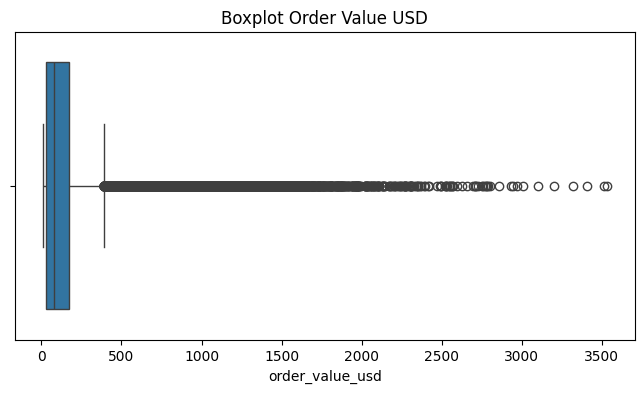

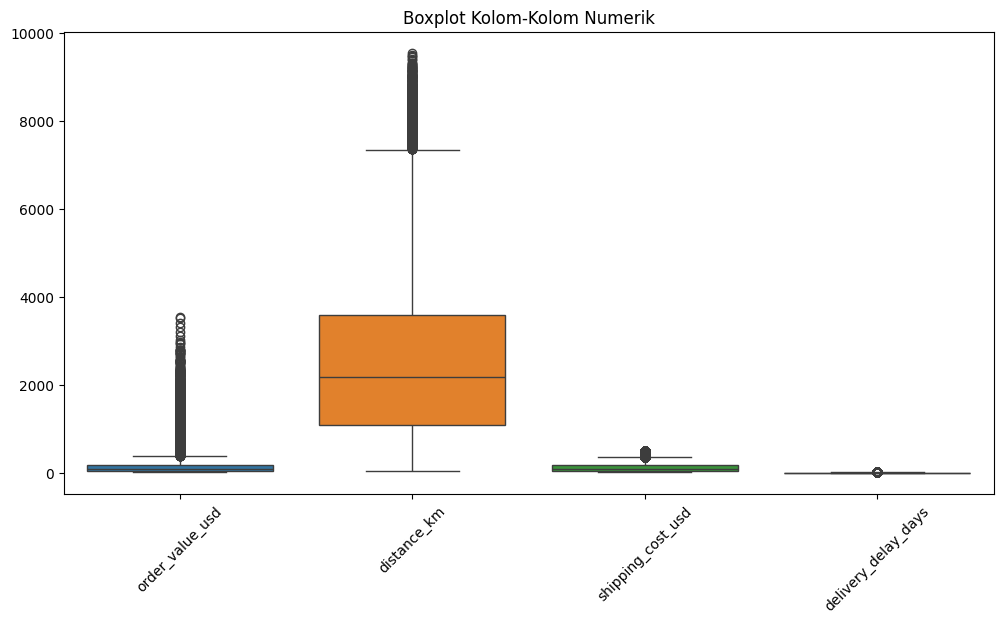

In [ ]:
# Cek outlier pada order value, dan kolom-kolom numerik
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['order_value_usd'])
plt.title('Boxplot Order Value USD')
plt.show()

# Boxplot untuk beberapa kolom numerik sekaligus
num_cols = [
    'order_value_usd',
    'distance_km',
    'shipping_cost_usd',
    'delivery_delay_days',
]
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[num_cols])
plt.xticks(rotation=45)
plt.title('Boxplot Kolom-Kolom Numerik')
plt.show()

In [ ]:
# Statistik Deskriptif & Distribusi Order Value
pd.options.display.max_columns = 999
pd.options.display.float_format = "{:.2f}".format
# Summary Statistik
print("=== STATISTIK DESKRIPTIF ORDER VALUE ===")
print(f"Mean (Rata-rata)   : ${df['order_value_usd'].mean():.2f}")
print(f"Median (Nilai Tengah): ${df['order_value_usd'].median():.2f}")
print(
    f"Percentile 90      : ${df['order_value_usd'].quantile(0.90):.2f}"
)
print(
    f"Percentile 95      : ${df['order_value_usd'].quantile(0.95):.2f}"
)
print(
    f"Percentile 99      : ${df['order_value_usd'].quantile(0.99):.2f}"
)


=== STATISTIK DESKRIPTIF ORDER VALUE ===
Mean (Rata-rata)   : $177.92
Median (Nilai Tengah): $76.84
Percentile 90      : $465.94
Percentile 95      : $798.01
Percentile 99      : $1454.05


In [ ]:
df['late_delivery'].value_counts(normalize=True)

,proportion
late_delivery,
True,0.56
False,0.44


In [ ]:
df["return_requested"].value_counts(normalize=True)

,proportion
return_requested,
False,0.83
True,0.17


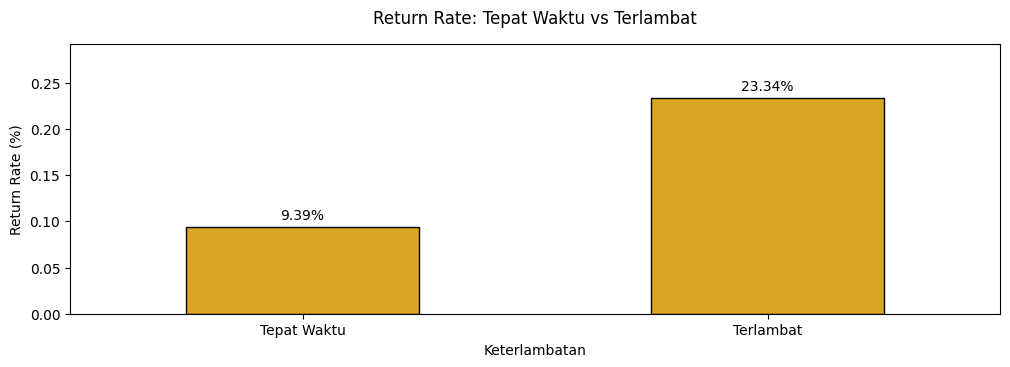

In [ ]:
# Analisis Korelasi Keterlambatan Pengiriman Terhadap Request Return
# 1. Konversi return_requested ke boolean/numeric (1 dan 0)
df['return_requested_num'] = df['return_requested'].apply(lambda x: 1 if str(x).strip().lower() in ['yes', 'true', '1'] else 0)

# 2. Hitung rata-rata
df_grouped = df.groupby('late_delivery')['return_requested_num'].mean().sort_index()

# 3. Rename indeks untuk label di grafik
df_grouped.index = df_grouped.index.map({False: 'Tepat Waktu', True: 'Terlambat'})

# 4. Buat grafik
warna_batang = ['goldenrod', 'goldenrod']
ax = df_grouped.plot(kind='bar', color=warna_batang, edgecolor='black', figsize=(12, 3.5))

plt.title("Return Rate: Tepat Waktu vs Terlambat", pad=15)
plt.xlabel("Keterlambatan")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=0)

max_val = df_grouped.max()
plt.ylim(0, max_val * 1.25)  # Beri ruang sedikit di atas batang

# 5. Tambahkan label persentase di atas batang
for bar in ax.patches:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + (max_val * 0.02), f'{yval:.2%}', ha='center', va='bottom')

plt.show()

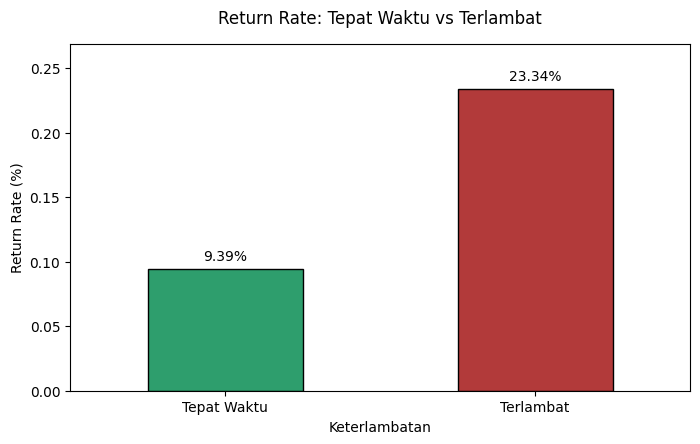

In [ ]:

df_grouped = df.groupby('late_delivery')['return_requested'].mean().sort_index()
warna_batang = ['#2e9e6d', '#b23a3a']
df_grouped = df_grouped.rename({False: 'Tepat Waktu', True: 'Terlambat'})
ax = df_grouped.plot(kind='bar',color= warna_batang, edgecolor='black', figsize=(8, 4.5))

plt.title("Return Rate: Tepat Waktu vs Terlambat", pad=15)
plt.xlabel("Keterlambatan")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=0)

max_val = df_grouped.max()
plt.ylim(0, max_val * 1.15)

for bar in ax.patches:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + (max_val * 0.02), f'{yval:.2%}', ha='center', va='bottom')

plt.show()

In [ ]:
# Analisis Kontribusi High-Value Orders (> $500)
# 1. Filter dataset untuk order_value_usd > 500
high_value_df = df[df['order_value_usd'] > 500]

# 2. Hitung persentase jumlah transaksi (Volume %)
total_orders = len(df)
high_value_orders = len(high_value_df)
order_share_pct = (high_value_orders / total_orders) * 100

# 3. Hitung kontribusi pendapatan (Revenue %)
total_revenue = df['order_value_usd'].sum()
high_value_revenue = high_value_df['order_value_usd'].sum()
revenue_share_pct = (high_value_revenue / total_revenue) * 100

print(f"Persentase Transaksi (> $500): {order_share_pct:.1f}%")
print(f"Kontribusi Pendapatan (> $500): {revenue_share_pct:.1f}%")

Persentase Transaksi (> $500): 9.3%
Kontribusi Pendapatan (> $500): 49.3%


In [ ]:
df["delivery_delay_days"].describe()

,delivery_delay_days
count,50000.00
mean,1.28
std,1.68
min,0.00
25%,0.00
50%,1.00
75%,2.00
max,13.00


In [ ]:
df["customer_rating"].value_counts().sort_index()

,count
customer_rating,
1,962
2,9621
3,15872
4,16953
5,6592


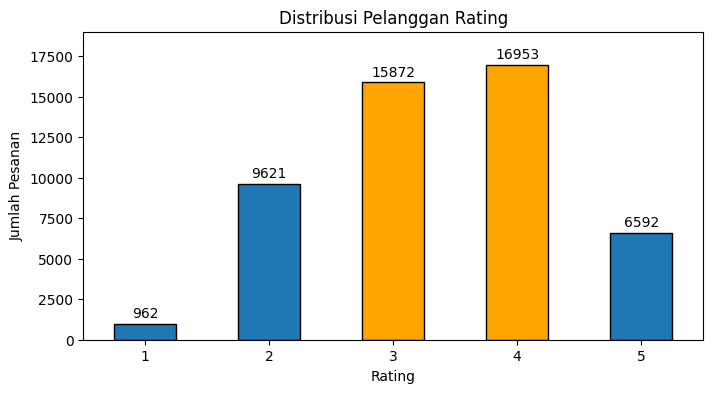

In [ ]:
# Analisis Distribusi Rating Pelanggan
warna_batang = ['C0', 'C0', 'orange', 'orange', 'C0']

fig, ax = plt.subplots(figsize=(8, 4))
ax = df["customer_rating"].value_counts().sort_index().plot(kind="bar", color=warna_batang, edgecolor="black")

plt.title("Distribusi Pelanggan Rating")
plt.xlabel("Rating")
plt.ylabel("Jumlah Pesanan")
plt.xticks(rotation=0)
plt.ylim(0, 19000)

for bar in ax.patches:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 200, f'{int(yval)}', ha='center', va='bottom')

plt.show()


In [ ]:
# 1. Rata-rata rating (tertimbang / rata-rata keseluruhan)
avg_rating = df['customer_rating'].mean()

# 2. Persentase pesanan diberi rating 3–4 (mayoritas)
mid_rating_pct = (df['customer_rating'].isin([3, 4]).sum() / len(df)) * 100

# 3. Persentase pesanan diberi rating rendah (1–2)
low_rating_pct = (df['customer_rating'].isin([1, 2]).sum() / len(df)) * 100

# Tampilkan hasil perhitungan
print(f"Rata-rata rating: {avg_rating:.2f} / 5")
print(f"Pesanan diberi rating 3–4: {mid_rating_pct:.1f}%")
print(f"Pesanan diberi rating rendah (1–2): {low_rating_pct:.1f}%")

Rata-rata rating: 3.37 / 5
Pesanan diberi rating 3–4: 65.6%
Pesanan diberi rating rendah (1–2): 21.2%


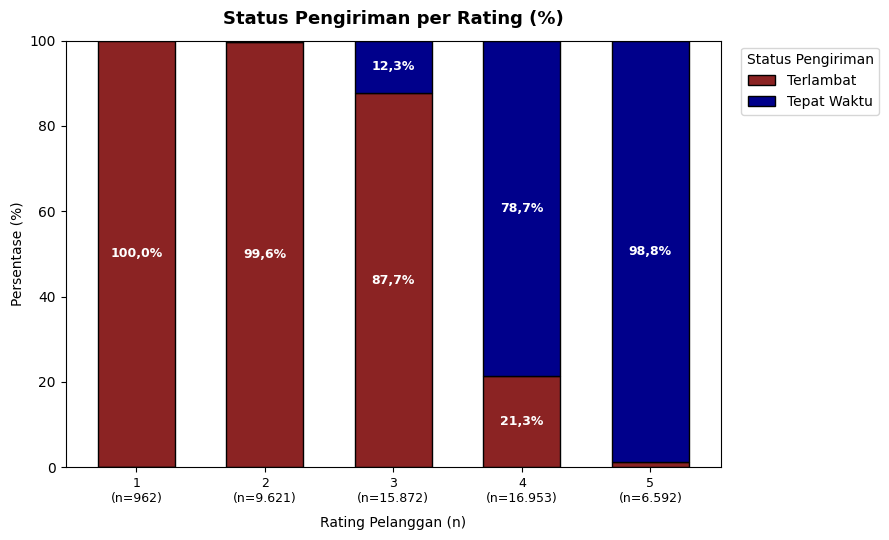

In [ ]:
# Analisis status pengiriman based on rating

# Pastikan 'late_delivery' didefinisikan dengan benar dari durasi delay
df["late_delivery"] = df["delivery_delay_days"] > 0

# 1. Pastikan kolom status pengiriman jelas (Terlambat vs Tepat Waktu)
df["status_pengiriman"] = df["late_delivery"].map(
    {True: "Terlambat", False: "Tepat Waktu"}
)

# Hitung jumlah sampel (n) per rating untuk label sumbu X
rating_counts = df["customer_rating"].value_counts().sort_index()

# 2. Buat crosstab dan normalisasi secara baris (100%)
ct = pd.crosstab(
    df["customer_rating"], df["status_pengiriman"], normalize="index"
) * 100

# Reorder kolom secara aman
available_cols = [col for col in ["Terlambat", "Tepat Waktu"] if col in ct.columns]
ct = ct[available_cols]

# 3. Plot 100% Stacked Bar Chart
fig, ax = plt.subplots(figsize=(9, 5.5))
color_map = {"Terlambat": "#8b2323", "Tepat Waktu": "#00008b"}
colors = [color_map[col] for col in ct.columns]

ct.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=colors,
    edgecolor="black",
    width=0.6,
)

# Perbaikan 3: Judul lebih ringkas
plt.title("Status Pengiriman per Rating (%)", fontsize=13, pad=12, fontweight="bold")
plt.xlabel("Rating Pelanggan (n)", fontsize=10, labelpad=8)
plt.ylabel("Persentase (%)", fontsize=10)

# Perbaikan 2: Format label sumbu X dengan format angka ribuan (e.g. 1 (n=962), 2 (n=9.621))
xtick_labels = [
    f"{rating}\n(n={count:,})".replace(",", ".")
    for rating, count in rating_counts.items()
]
plt.xticks(ticks=range(len(xtick_labels)), labels=xtick_labels, rotation=0, fontsize=9)

plt.ylim(0, 100)
plt.legend(title="Status Pengiriman", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)

# Perbaikan 1: Sembunyikan label persentase jika di bawah 3% (< 3.0) agar tidak menumpuk/terpotong
for container in ax.containers:
    labels = [
        f"{v.get_height():.1f}%".replace(".", ",") if v.get_height() >= 3.0 else ""
        for v in container
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        color="white",
        fontweight="bold",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [ ]:
mid = df[df['customer_rating'].isin([3, 4])]
print(mid['late_delivery'].value_counts())                  # jumlah
print(mid['late_delivery'].value_counts(normalize=True)*100)  # persentase

late_delivery
True     17535
False    15290
Name: count, dtype: int64
late_delivery
True    53.42
False   46.58
Name: proportion, dtype: float64


Lebih dari separuh pesanan (53,42%) yang masuk dalam kelompok rating 3 & 4 ternyata mengalami keterlambatan pengiriman. Ini mengindikasikan bahwa masalah keterlambatan sudah menyasar kelompok pelanggan utama yang sebenarnya berpotensi memberikan rating sempurna (rating 5)

In [ ]:
df.groupby('late_delivery')['customer_rating'].mean()

,customer_rating
late_delivery,
False,4.21
True,2.73


In [ ]:
# Bivariat: late_delivery vs rating (mendukung Q1 & Q2)
df.groupby("late_delivery")["customer_rating"].mean()

,customer_rating
late_delivery,
False,4.21
True,2.73


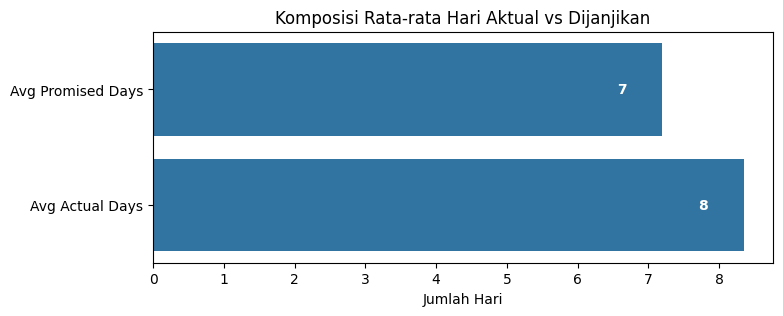

In [ ]:
# Avg Actual days vs Avg Promised days
# 1. Hitung nilai rata-rata dari masing-masing kolom
avg_promised = df['promised_delivery_days'].mean()
avg_actual = df['actual_delivery_days'].mean()

# 2. Buat DataFrame baru untuk plotting
avg_df = pd.DataFrame({
    'Kategori': ['Avg Promised Days', 'Avg Actual Days'],
    'Rata-rata': [avg_promised, avg_actual]
})

# 3. Buat Horizontal Bar Chart
plt.figure(figsize=(8, 3))
ax = sns.barplot(data=avg_df, x='Rata-rata', y='Kategori')

# Label nilai angka di dalam batang
for p in ax.patches:
    ax.annotate(f'{p.get_width():.0f}',
                (p.get_width() - 0.5, p.get_y() + p.get_height() / 2.),
                ha='right', va='center', color='white', fontweight='bold')

plt.title('Komposisi Rata-rata Hari Aktual vs Dijanjikan')
plt.xlabel('Jumlah Hari')
plt.ylabel('')
plt.show()

In [ ]:
# Anlisis Rating based on Carrier
# Ensure 'late_delivery' is boolean for mean calculation
df["late_delivery"] = df["late_delivery"] == "Yes"

df.groupby("carrier").agg(
    late_rate=("late_delivery", "mean"),
    avg_rating=("customer_rating", "mean")
).sort_values("late_rate", ascending=False)

/tmp/ipykernel_514/715594956.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("carrier").agg(


,late_rate,avg_rating
carrier,,
BlueRoute,0.00,3.30
EagleCourier,0.00,3.39
FastTrack Logistics,0.00,3.37
GlobalExpress,0.00,3.23
ParcelPro,0.00,3.43
PrimeDelivery,0.00,3.29
SpeedyCargo,0.00,3.45
SwiftShip,0.00,3.50


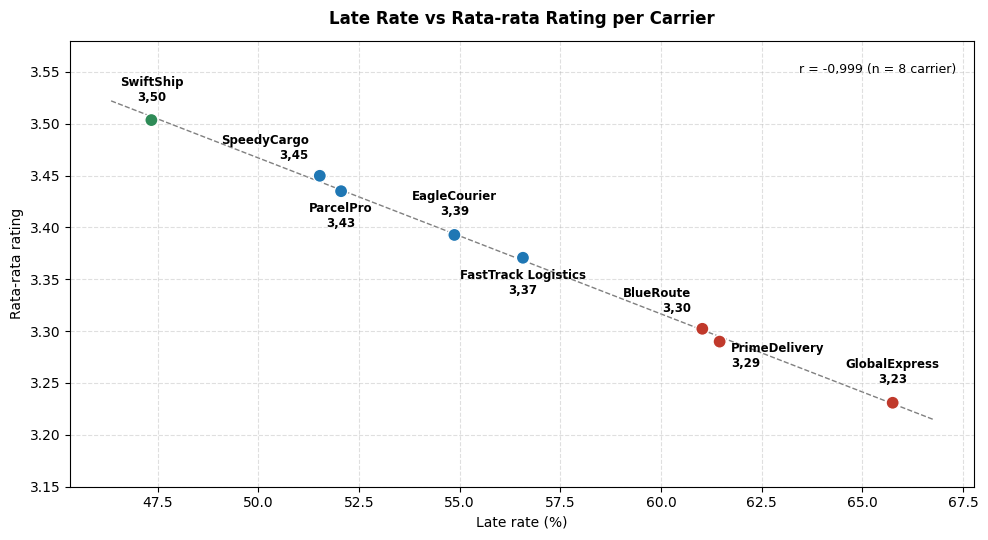

In [ ]:
# Visualisasi Carrier's Rating
df["late"] = df["delivery_delay_days"] > 0

# Late rate (%) dan rata-rata rating per carrier
g = (df.groupby("carrier", observed=False)
       .agg(late_rate=("late", "mean"), avg_rating=("customer_rating", "mean"))
       .assign(late_rate=lambda d: d["late_rate"] * 100)
       .sort_values("late_rate"))

# Garis tren + korelasi
slope, intercept = np.polyfit(g["late_rate"], g["avg_rating"], 1)
r = np.corrcoef(g["late_rate"], g["avg_rating"])[0, 1]

# Merah = 3 carrier berisiko, hijau = SwiftShip, biru = lainnya
risiko = ["GlobalExpress", "PrimeDelivery", "BlueRoute"]
warna = ["#c0392b" if c in risiko else "#2e8b57" if c == "SwiftShip" else "#1f77b4" for c in g.index]

# Posisi label (geser_x, geser_y, rata) agar tidak saling menimpa
offset = {
    "SwiftShip":           (0,  14, "center"),
    "SpeedyCargo":         (-8, 12, "right"),
    "ParcelPro":           (0, -26, "center"),
    "EagleCourier":        (0,  14, "center"),
    "FastTrack Logistics": (0, -26, "center"),
    "BlueRoute":           (-8, 12, "right"),
    "PrimeDelivery":       (8, -18, "left"),
    "GlobalExpress":       (0,  14, "center"),
}

fig, ax = plt.subplots(figsize=(10, 5.5))
xs = np.linspace(g["late_rate"].min() - 1, g["late_rate"].max() + 1, 50)
ax.plot(xs, slope * xs + intercept, "--", color="gray", linewidth=1, zorder=1)
ax.scatter(g["late_rate"], g["avg_rating"], s=90, c=warna, zorder=2, edgecolor="white")

for nama, row in g.iterrows():
    dx, dy, ha = offset[nama]
    ax.annotate(f"{nama}\n{row.avg_rating:.2f}".replace(".", ","),
                (row.late_rate, row.avg_rating), textcoords="offset points",
                xytext=(dx, dy), ha=ha, fontsize=8.5, fontweight="bold")

ax.set_title("Late Rate vs Rata-rata Rating per Carrier", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Late rate (%)")
ax.set_ylabel("Rata-rata rating")
ax.set_ylim(3.15, 3.58)
ax.grid(linestyle="--", alpha=0.4)
ax.text(0.98, 0.95, f"r = {r:.3f}".replace(".", ",") + f" (n = {len(g)} carrier)",
        transform=ax.transAxes, ha="right", va="top", fontsize=9)
plt.tight_layout()
plt.show()

/tmp/ipykernel_514/3202405821.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  w = (df.groupby('weather_condition')


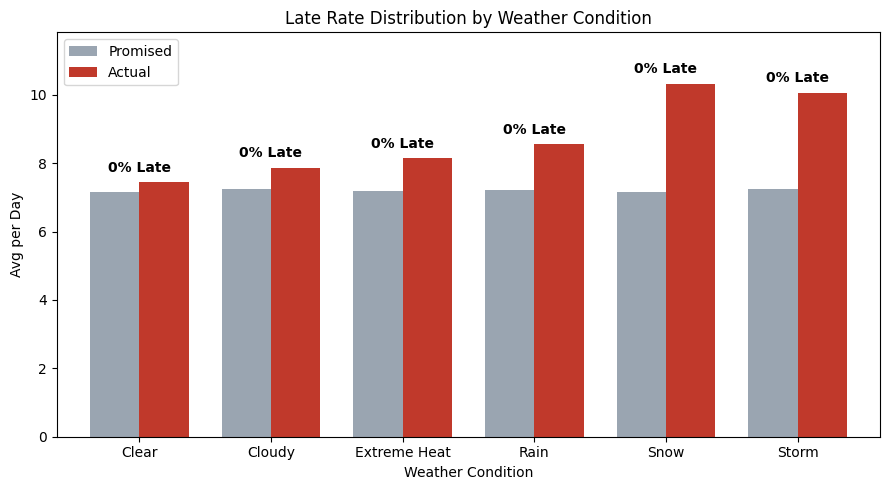

In [ ]:
# Analisis Late Rate by Weather

w = (df.groupby('weather_condition')
       .agg(janji=('promised_delivery_days', 'mean'),
            aktual=('actual_delivery_days', 'mean'),
            late=('late_delivery', lambda s: s.astype(str).str.upper().eq('TRUE').mean() * 100))
       .sort_values('late'))

ax = w[['janji', 'aktual']].plot(kind='bar', figsize=(9, 5),
                                 color=['#9aa5b1', '#c0392b'], width=0.75)

for i, (_, r) in enumerate(w.iterrows()):
    ax.text(i, max(r.janji, r.aktual) + 0.3, f"{r.late:.0f}% Late",
            ha='center', fontsize=10, fontweight='bold')

ax.set_title('Late Rate Distribution by Weather Condition')
ax.set_ylabel('Avg per Day')
ax.set_xlabel('Weather Condition')
ax.legend(['Promised', 'Actual'])
ax.set_ylim(0, w[['janji', 'aktual']].max().max() + 1.5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:


# 1. Hitung rata-rata durasi berdasarkan kondisi cuaca
tabel = (
    df.groupby("weather_condition")[["promised_delivery_days", "actual_delivery_days"]]
    .mean()
    .round(2)
)

# 2. Hitung selisih/gap keterlambatan (Actual - Promised)
tabel["delivery_gap"] = (tabel["actual_delivery_days"] - tabel["promised_delivery_days"]).round(2)

# 3. Urutkan data berdasarkan durasi aktual dan rapikan nama kolom
tabel = (
    tabel.sort_values("actual_delivery_days")
    .rename(columns={
        "promised_delivery_days": "Promised Delivery Day",
        "actual_delivery_days": "Actual Delivery Day",
        "delivery_gap": "Delivery Gap (Days)"
    })
)
tabel.index.name = "Weather"

# 4. Format desimal dengan koma untuk standar Indonesia
tabel_id = tabel.map(lambda x: f"{x:.2f}".replace(".", ",")).reset_index()

# Tampilkan hasil
tabel_id

/tmp/ipykernel_514/3509678041.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("weather_condition")[["promised_delivery_days", "actual_delivery_days"]]


,Weather,Promised Delivery Day,Actual Delivery Day,Delivery Gap (Days)
0,Clear,"7,16","7,44","0,28"
1,Cloudy,"7,24","7,87","0,63"
2,Extreme Heat,"7,18","8,14","0,96"
3,Rain,"7,21","8,55","1,34"
4,Storm,"7,24","10,06","2,82"
5,Snow,"7,16","10,33","3,17"


In [ ]:


df = pd.read_csv(dataset1)
# 1. Korelasi Pearson: Durasi Keterlambatan vs Customer Rating
corr, p1 = stats.pearsonr(df["delivery_delay_days"], df["customer_rating"])

print("=" * 60)
print("1. KORELASI PEARSON (delay_days vs rating)")
print("=" * 60)
print(f"Koefisien Korelasi (r) : {corr:.4f}")
print(f"p-value                : {p1:.6e}")
print(
    f"Kesimpulan             : {'Korelasi Negatif Signifikan' if p1 < 0.05 else 'Tidak Signifikan'}\n"
)

# 2. Independent T-test: Rating (Late vs On-time)
# Menangani filter baik jika berisi boolean (True/False) maupun string ("Yes"/"No")
is_late = df["late_delivery"].isin([True, "Yes", 1])

late_rating = df[is_late]["customer_rating"].dropna()
ontime_rating = df[~is_late]["customer_rating"].dropna()

t_stat, p2 = stats.ttest_ind(late_rating, ontime_rating, equal_var=False)

print("=" * 60)
print("2. T-TEST (Rating: Late vs On-time)")
print("=" * 60)
print(f"Mean Rating - Late     : {late_rating.mean():.3f}")
print(f"Mean Rating - OnTime   : {ontime_rating.mean():.3f}")
print(f"T-statistic            : {t_stat:.4f}")
print(f"p-value                : {p2:.6e}")
print(
    f"Kesimpulan             : Perbedaan rating {'sangat signifikan' if p2 < 0.05 else 'tidak signifikan'}\n"
)

# 3. Chi-Square Test: Late Delivery vs Return Requested
ct = pd.crosstab(
    df["late_delivery"],
    df["return_requested"],
    margins=True,
    margins_name="Total",
)

chi2, p3, dof, expected = stats.chi2_contingency(
    pd.crosstab(df["late_delivery"], df["return_requested"])
)

print("=" * 60)
print("3. CHI-SQUARE TEST (Late Delivery vs Return Requested)")
print("=" * 60)
print(f"Chi-square Value       : {chi2:.4f}")
print(f"p-value                : {p3:.6e}")
print(f"Degrees of Freedom     : {dof}")
print("\nTabel Kontingensi (Crosstab):")
print(ct)
print("=" * 60)

1. KORELASI PEARSON (delay_days vs rating)
Koefisien Korelasi (r) : -0.5080
p-value                : 0.000000e+00
Kesimpulan             : Korelasi Negatif Signifikan

2. T-TEST (Rating: Late vs On-time)
Mean Rating - Late     : 2.725
Mean Rating - OnTime   : 4.206
T-statistic            : -249.0509
p-value                : 0.000000e+00
Kesimpulan             : Perbedaan rating sangat signifikan

3. CHI-SQUARE TEST (Late Delivery vs Return Requested)
Chi-square Value       : 1676.2772
p-value                : 0.000000e+00
Degrees of Freedom     : 1

Tabel Kontingensi (Crosstab):
return_requested     No   Yes  Total
late_delivery                       
No                19787  2051  21838
Yes               21588  6574  28162
Total             41375  8625  50000


In [ ]:
# SEGMENTASI DATA (BINNING FOR BUSINESS INSIGHT)

bins = [0, 200, 500, np.inf]
labels = ['Low Value (<$200)', 'Medium Value ($200-$500)', 'High Value (>$500)']

df['order_value_segment'] = pd.cut(
    df['order_value_usd'], bins=bins, labels=labels
)

# Analisis ringkas per segmen
segment_summary = (
    df.groupby('order_value_segment', observed=False)
    .agg(
        total_orders=('order_id', 'count'),
        total_revenue=('order_value_usd', 'sum'),
        avg_order_value=('order_value_usd', 'mean'),
    )
    .reset_index()
)

segment_summary['pct_orders'] = (
    segment_summary['total_orders'] / len(df) * 100
)
segment_summary['pct_revenue'] = (
    segment_summary['total_revenue'] / df['order_value_usd'].sum() * 100
)

print('\n=== RINGKASAN SEGMENTASI TRANSAKSI ===')
display(segment_summary)


=== RINGKASAN SEGMENTASI TRANSAKSI ===


,order_value_segment,total_orders,total_revenue,avg_order_value,pct_orders,pct_revenue
0,Low Value (<$200),39142,2587789.18,66.11,78.28,29.09
1,Medium Value ($200-$500),6220,1924299.33,309.37,12.44,21.63
2,High Value (>$500),4638,4383766.82,945.18,9.28,49.28


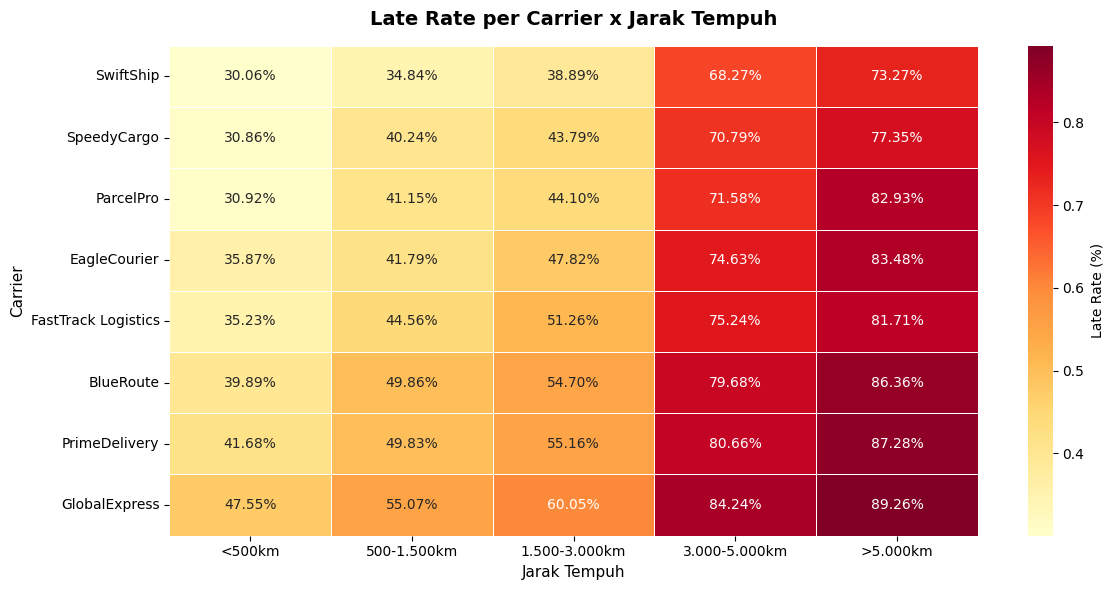

In [ ]:
#Matrix Late Rate: SwiftShip Unggul Konsisten di Semua Kategori Jarak

# 1. Pastikan kolom 'distance_group' tersedia jika terhapus akibat pembacaan ulang dataset
if 'distance_group' not in df.columns:
    conditions = [
        (df['distance_km'] < 500),
        (df['distance_km'] >= 500) & (df['distance_km'] < 1500),
        (df['distance_km'] >= 1500) & (df['distance_km'] < 3000),
        (df['distance_km'] >= 3000) & (df['distance_km'] < 5000),
        (df['distance_km'] >= 5000)
    ]
    choices = ['<500km', '500-1.500km', '1.500-3.000km', '3.000-5.000km', '>5.000km']
    df['distance_group'] = np.select(conditions, choices, default='Unknown')

# 2. Konversi 'late_delivery' secara aman (menangani string 'Yes'/'No' maupun boolean)
df['late_delivery_num'] = df['late_delivery'].map({'Yes': 1, 'No': 0, True: 1, False: 0}).fillna(0).astype(int)

# 3. Buat Pivot Table persentase keterlambatan (Carrier x Distance Group)
pivot_late_rate = df.pivot_table(
    index='carrier',
    columns='distance_group',
    values='late_delivery_num',
    aggfunc='mean'
)

# 4. Urutkan kolom jarak agar sesuai urutan rentang km
order_distance = ['<500km', '500-1.500km', '1.500-3.000km', '3.000-5.000km', '>5.000km']
pivot_late_rate = pivot_late_rate.reindex(columns=[col for col in order_distance if col in pivot_late_rate.columns])

# 5. Urutkan carrier berdasarkan rata-rata late rate terendah ke tertinggi
pivot_late_rate['Total'] = df.groupby('carrier')['late_delivery_num'].mean()
pivot_late_rate = pivot_late_rate.sort_values('Total', ascending=True)

# 6. Visualisasi Heatmap Matrix
plt.figure(figsize=(12, 6))
sns.heatmap(
    pivot_late_rate.drop(columns=['Total'], errors='ignore'),
    annot=True,
    fmt=".2%",          # Format persentase (contoh: 30.06%)
    cmap="YlOrRd",       # Gradasi warna Kuning -> Oranye -> Merah
    cbar_kws={'label': 'Late Rate (%)'},
    linewidths=0.5,
    linecolor='white'
)

plt.title("Late Rate per Carrier x Jarak Tempuh", fontsize=14, pad=15, fontweight='bold')
plt.xlabel("Jarak Tempuh", fontsize=11)
plt.ylabel("Carrier", fontsize=11)
plt.tight_layout()

plt.show()

In [ ]:
# What-If Analysis
# 1.Estimasi Target
# df['distance_km'], df['delivery_delay_days'], df['order_value_usd']

# Kategori Jarak
conditions = [
    (df['distance_km'] < 500),
    (df['distance_km'] >= 500) & (df['distance_km'] < 1500),
    (df['distance_km'] >= 1500) & (df['distance_km'] < 3000),
    (df['distance_km'] >= 3000) & (df['distance_km'] < 5000),
    (df['distance_km'] >= 5000)
]
choices = ['<500km', '500-1.500km', '1.500-3.000km', '3.000-5.000km', '>5.000km']
# Perbaikan: Menambahkan default='Unknown' agar bertipe string dan tidak bentrok dengan default integer 0
df['distance_group'] = np.select(conditions, choices, default='Unknown')

# Flag Keterlambatan Aktual
df['is_delayed'] = df['delivery_delay_days'] > 0

# 2. Hitung Profil Baseline Saat Ini
baseline = df.groupby('distance_group').agg(
    total_orders=('order_value_usd', 'count'),
    actual_late_rate=('is_delayed', 'mean')
).reset_index()

baseline['order_share'] = baseline['total_orders'] / len(df)

# 3. Simulasi Skenario Dynamic SLA
# Misal: Tambah SLA 2 hari untuk jarak >3000km
# Late rate baru dihitung jika keterlambatan > 2 hari
df['is_delayed_simulated'] = np.where(
    df['distance_km'] >= 3000,
    df['delivery_delay_days'] > 2, # Hanya dianggap terlambat jika delay > 2 hari
    df['delivery_delay_days'] > 0
)

# 4. Hasil Late Rate Baru
simulated_total_late_rate = df['is_delayed_simulated'].mean() * 100

print(f"Total Late Rate Aktual   : {df['is_delayed'].mean()*100:.2f}%")
print(f"Total Late Rate Simulasi : {simulated_total_late_rate:.2f}%")

Total Late Rate Aktual   : 56.32%
Total Late Rate Simulasi : 41.37%


In [ ]:
df.to_csv("cleaned_ecommerce_delivery.csv", index=False)
print("Selesai. Shape akhir:", df.shape)

Selesai. Shape akhir: (50000, 35)
